# 🛒 Classifying orders: *high-value* or *standard* — with live inputs

**What this notebook shows (4 steps):**
1. **The dataset** — the real file, its rows and columns.
2. **The class** — the yes/no column we predict, and where it comes from.
3. **The proof** — how often the model is right and wrong (confusion matrix) on orders it has never seen.
4. **Your inputs** — look up any row, type in a brand-new order, change the class definition, and compare any two groups.

> **How to run:** Runtime ▸ **Run all**, wait until the last cell finishes (about a minute). Then change the forms in steps 4–7 and press ▶.

In [1]:
# --- setup (also hides harmless warning messages that Colab's own engine prints) ---
import io, warnings
warnings.filterwarnings("ignore")
try:
    import datetime as _dt, jupyter_client.session as _jcs, ipykernel.kernelbase as _kb
    _now = lambda: _dt.datetime.now(_dt.timezone.utc)
    _jcs.utcnow = _now
    if hasattr(_kb, "now"):
        _kb.now = _now
except Exception:
    pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PALETTE = ["#E8497B", "#8E7DBE", "#F7C948", "#5AA7A7"]
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 40
SEED = 42
print("Ready ✅")

Ready ✅


## 1. The dataset
A real retail sales file (Superstore, Kaggle): **one row = one product line on an order**. It is downloaded straight from its source link, so you can see exactly where it comes from.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/khairalanam/sales-forecast-excel-project/main/train.csv"

def load_data():
    try:
        return pd.read_csv(DATA_URL)
    except Exception:
        print("Download blocked — please upload train.csv (or sample_superstore.csv) instead.")
        from google.colab import files
        up = files.upload()
        return pd.read_csv(io.BytesIO(next(iter(up.values()))))

raw = load_data()
print(f"SOURCE: {DATA_URL}")
print(f"THE RAW FILE has {len(raw):,} rows and {raw.shape[1]} columns.\n")

# one tiny clean-up step: remove the 1 repeated row, and turn the date text into real dates
df = raw.drop_duplicates(subset=[c for c in raw.columns if c != "Row ID"]).reset_index(drop=True)
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%d/%m/%Y")
df["Ship Date"]  = pd.to_datetime(df["Ship Date"],  format="%d/%m/%Y")
df["order_month"], df["order_quarter"], df["order_year"] = df["Order Date"].dt.month, df["Order Date"].dt.quarter, df["Order Date"].dt.year
df["ship_days"] = (df["Ship Date"] - df["Order Date"]).dt.days
print(f"After removing {len(raw) - len(df)} repeated row: {len(df):,} rows.  (Only one column, Sales, is a money amount.)\n")

display(pd.DataFrame({"column #": range(1, raw.shape[1] + 1), "column": raw.columns, "example (row 1)": [str(v)[:40] for v in raw.iloc[0]]}).set_index("column #"))
raw.head(5)

SOURCE: https://raw.githubusercontent.com/khairalanam/sales-forecast-excel-project/main/train.csv
THE RAW FILE has 9,800 rows and 18 columns.

After removing 1 repeated row: 9,799 rows.  (Only one column, Sales, is a money amount.)



,column,example (row 1)
column #,,
1,Row ID,1
2,Order ID,CA-2017-152156
3,Order Date,08/11/2017
4,Ship Date,11/11/2017
5,Ship Mode,Second Class
6,Customer ID,CG-12520
7,Customer Name,Claire Gute
8,Segment,Consumer
9,Country,United States


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37


## 2. The class — the yes/no answer we want to predict
In data mining the **class** is the *target column*: the labels the model learns to predict (like `spam` = yes / no for e-mails).

Our dataset has no ready-made label, so we **create one from the `Sales` column**:

> **high-value (1)** = the sale is in the **top 25%** of all sales  ·  **standard (0)** = everything else

The dividing line is the **75th percentile** of `Sales` — sort all sales from smallest to biggest, go 75% of the way up, and read off the price.

In [3]:
cut_off = df["Sales"].quantile(0.75)                       # <-- the dividing line, in dollars
df["high_value"] = (df["Sales"] >= cut_off).astype(int)    # <-- THE CLASS COLUMN: 1 = high-value, 0 = standard
df["class_name"] = np.where(df["high_value"] == 1, "high-value", "standard")

print(f"CUT-OFF = ${cut_off:,.2f}   (in dollars — the dividing line)\n")
print("COUNT OF ROWS in each class (these are numbers of rows, not dollars):")
print(df["class_name"].value_counts().to_string())
print(f"\n→ {int(df['high_value'].sum()):,} high-value rows = {df['high_value'].mean():.0%} of {len(df):,} rows.   The new column is called  high_value.\n")
print("THE CLASS COLUMN next to real rows (Sales is on the left, the class label on the right):")
df[["Row ID", "Order ID", "Sub-Category", "Sales", "high_value", "class_name"]].sample(8, random_state=5)

CUT-OFF = $210.57   (in dollars — the dividing line)

COUNT OF ROWS in each class (these are numbers of rows, not dollars):
class_name
standard      7349
high-value    2450

→ 2,450 high-value rows = 25% of 9,799 rows.   The new column is called  high_value.

THE CLASS COLUMN next to real rows (Sales is on the left, the class label on the right):


,Row ID,Order ID,Sub-Category,Sales,high_value,class_name
4211,4213,CA-2015-166457,Art,6.56,0,standard
9563,9565,CA-2016-161242,Paper,11.76,0,standard
944,945,CA-2016-120880,Storage,540.57,1,high-value
5426,5428,US-2017-108497,Bookcases,599.16,1,high-value
9614,9616,CA-2015-128524,Binders,"2,033.58",1,high-value
329,330,US-2017-141544,Labels,100.24,0,standard
5991,5993,US-2018-163300,Chairs,184.75,0,standard
9515,9517,CA-2016-123939,Phones,26.98,0,standard


**See the labelling happen.** First the same rows *before* and *after* the label column is added, then a picture of the dividing line: every sale to the left of it is labelled **standard**, every sale to the right is labelled **high-value**.

BEFORE labelling — rows as they came in the file (there is no class column):


,Row ID,Sub-Category,Sales
4211,4213,Art,6.56
9563,9565,Paper,11.76
944,945,Storage,540.57
5426,5428,Bookcases,599.16
9614,9616,Binders,"2,033.58"



AFTER labelling — the same rows, with the new class column added on the right (highlighted):


,Row ID,Sub-Category,Sales,high_value,class_name
4211,4213,Art,6.560000,0,standard
9563,9565,Paper,11.760000,0,standard
944,945,Storage,540.570000,1,high-value
5426,5428,Bookcases,599.165000,1,high-value
9614,9616,Binders,2033.584000,1,high-value


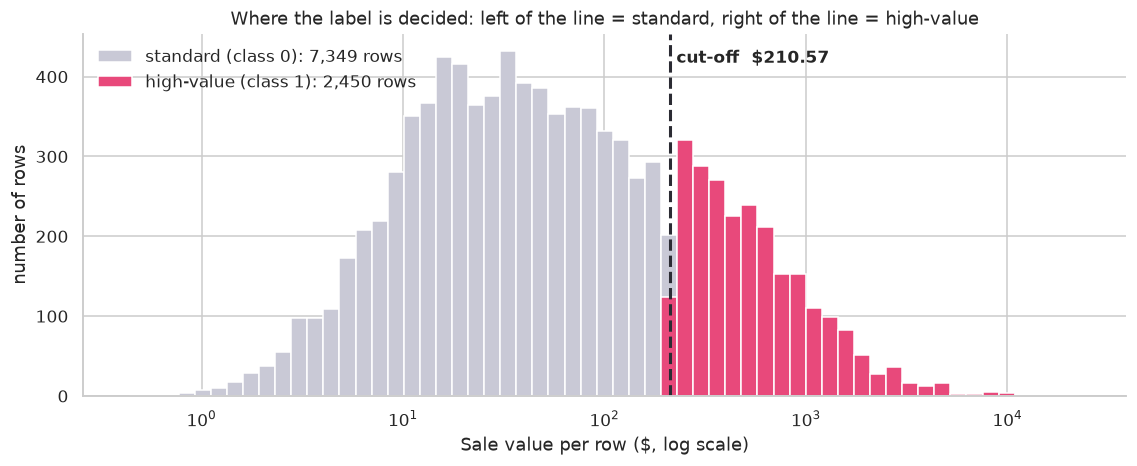

In [4]:
before = df[["Row ID", "Sub-Category", "Sales"]].sample(5, random_state=5)
print("BEFORE labelling — rows as they came in the file (there is no class column):")
display(before)
print("\nAFTER labelling — the same rows, with the new class column added on the right (highlighted):")
after = before.assign(high_value=df.loc[before.index, "high_value"], class_name=df.loc[before.index, "class_name"])
display(after.style.set_properties(subset=["high_value", "class_name"], **{"background-color": "#FBD4E0", "font-weight": "bold"}))

fig, ax = plt.subplots(figsize=(10.5, 4.4))
bins = np.logspace(np.log10(df["Sales"].min()), np.log10(df["Sales"].max()), 60)
ax.hist(df.loc[df["high_value"] == 0, "Sales"], bins=bins, color="#C9C9D6", label=f"standard (class 0): {int((df['high_value'] == 0).sum()):,} rows")
ax.hist(df.loc[df["high_value"] == 1, "Sales"], bins=bins, color=PALETTE[0], label=f"high-value (class 1): {int(df['high_value'].sum()):,} rows")
ax.axvline(cut_off, color="#2B2B33", ls="--", lw=2)
ax.text(cut_off * 1.08, ax.get_ylim()[1] * 0.92, f"cut-off  ${cut_off:,.2f}", fontsize=11, fontweight="bold")
ax.set_xscale("log")
ax.set(title="Where the label is decided: left of the line = standard, right of the line = high-value",
       xlabel="Sale value per row ($, log scale)", ylabel="number of rows")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()

### Labelled data = clues (features) + a label
This is the same idea as an **e-mail spam filter** or a **movie vs TV-show** classifier:

| Idea | E-mail spam filter | Movie vs TV show | **Our data** |
|---|---|---|---|
| One row is… | one e-mail | one title | **one order line** |
| **Features** (the clues) | words, sender, length | length, genre, year | **product, customer type, region, shipping, date** |
| **Label** (the class) | spam / not spam | movie / TV show | **high-value / standard** |
| **Labelled data** | e-mails already marked spam or not | titles already marked movie or show | **order lines already marked high-value or standard** |
| **Training** | learn from labelled e-mails | learn from labelled titles | **learn from 80% of the labelled orders** |
| **Testing** | check on e-mails it hasn't seen | check on titles it hasn't seen | **check on the other 20%** |
| **Prediction** | new e-mail → spam? | new title → movie? | **new order → high-value?** |

In [5]:
clues = ["Category", "Sub-Category", "Segment", "Region", "Ship Mode", "order_month", "order_year", "ship_days"]
labelled = df[clues + ["class_name"]].rename(columns={"class_name": "LABEL"})
print(f"LABELLED DATA — the clues (features) on the left, the LABEL on the right. All {len(labelled):,} rows have a label:\n")
display(labelled.sample(8, random_state=11))
print("\nHow many rows carry each label:")
print(labelled["LABEL"].value_counts().to_string())

LABELLED DATA — the clues (features) on the left, the LABEL on the right. All 9,799 rows have a label:



,Category,Sub-Category,Segment,Region,Ship Mode,order_month,order_year,ship_days,LABEL
2760,Office Supplies,Paper,Home Office,West,First Class,5,2015,3,standard
5481,Technology,Accessories,Corporate,West,Standard Class,10,2018,6,high-value
5693,Furniture,Chairs,Corporate,East,Standard Class,12,2016,6,high-value
905,Office Supplies,Paper,Consumer,West,Standard Class,4,2017,4,standard
4722,Office Supplies,Labels,Consumer,South,Same Day,5,2017,0,standard
9188,Office Supplies,Storage,Home Office,East,Standard Class,8,2016,4,high-value
5838,Office Supplies,Paper,Home Office,South,Second Class,9,2016,4,standard
8339,Office Supplies,Paper,Consumer,South,Standard Class,11,2015,6,standard



How many rows carry each label:
LABEL
standard      7349
high-value    2450


**The whole labelled dataset.** Every one of the 9,799 rows has a label. The table below is all of them, with the price (`Sales`) beside the label so you can see the rule at work. In Colab, click the small **table icon** at the top-right of the output to scroll through all rows, sort, and **filter by LABEL**. Colab also saves it as a file, `labelled_orders.csv` (open the 📁 Files pane on the left and double-click it).

In [6]:
labelled_all = df[["Row ID", "Order ID", "Order Date", "Category", "Sub-Category", "Segment", "Region", "Ship Mode", "Sales", "class_name"]].rename(columns={"class_name": "LABEL"})
try:
    import google.colab                           # this import only works inside Google Colab
    labelled_all.to_csv("labelled_orders.csv", index=False)
    print("Saved labelled_orders.csv — open the 📁 Files pane on the left and double-click it to see the LABEL column in the file itself.\n")
except ImportError:
    pass
print(f"ALL {len(labelled_all):,} rows, each with its LABEL in the last column:  standard = {int((labelled_all['LABEL'] == 'standard').sum()):,}  ·  high-value = {int((labelled_all['LABEL'] == 'high-value').sum()):,}")
labelled_all

ALL 9,799 rows, each with its LABEL in the last column:  standard = 7,349  ·  high-value = 2,450


,Row ID,Order ID,Order Date,Category,Sub-Category,Segment,Region,Ship Mode,Sales,LABEL
0,1,CA-2017-152156,2017-11-08,Furniture,Bookcases,Consumer,South,Second Class,261.96,high-value
1,2,CA-2017-152156,2017-11-08,Furniture,Chairs,Consumer,South,Second Class,731.94,high-value
2,3,CA-2017-138688,2017-06-12,Office Supplies,Labels,Corporate,West,Second Class,14.62,standard
3,4,US-2016-108966,2016-10-11,Furniture,Tables,Consumer,South,Standard Class,957.58,high-value
4,5,US-2016-108966,2016-10-11,Office Supplies,Storage,Consumer,South,Standard Class,22.37,standard
...,...,...,...,...,...,...,...,...,...,...
9794,9796,CA-2017-125920,2017-05-21,Office Supplies,Binders,Corporate,Central,Standard Class,3.80,standard
9795,9797,CA-2016-128608,2016-01-12,Office Supplies,Art,Corporate,East,Standard Class,10.37,standard
9796,9798,CA-2016-128608,2016-01-12,Technology,Phones,Corporate,East,Standard Class,235.19,high-value
9797,9799,CA-2016-128608,2016-01-12,Technology,Phones,Corporate,East,Standard Class,26.38,standard


## 3. The proof — can a model predict the class?
We hide 20% of the rows (the **test set**), train a **Random Forest** on the other 80%, then check its answers on the hidden rows. The model is **never shown `Sales`** — only the product, customer type, region, shipping and date.

The **confusion matrix** is the scoreboard: rows = the truth, columns = the model's guess.

Trained on 7,839 rows, tested on 1,960 rows the model never saw (1,470 standard + 490 high-value).



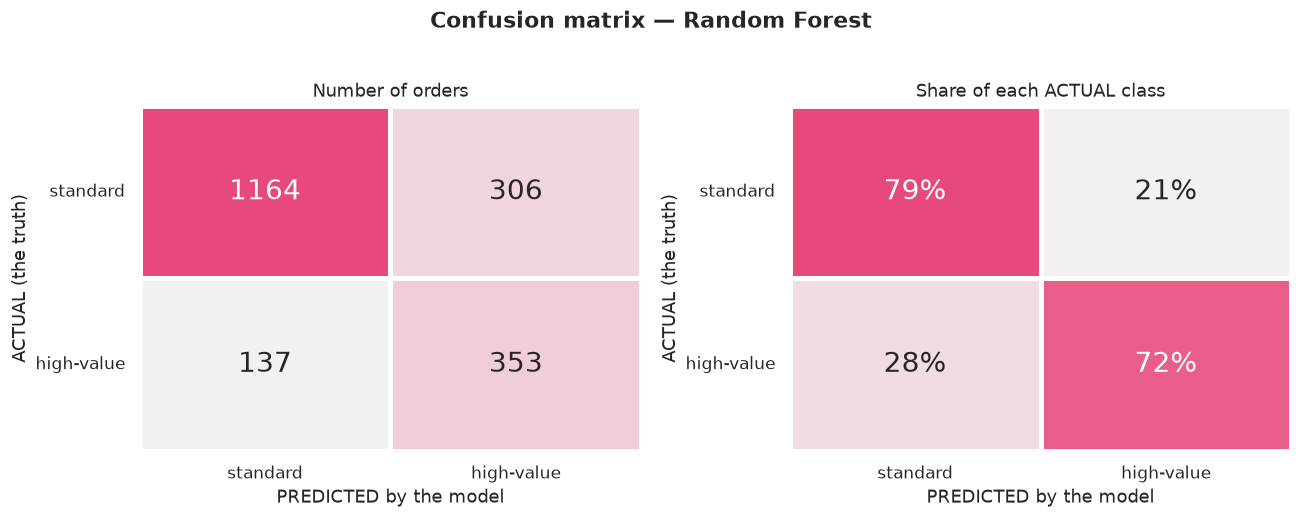

✔ 1,164 standard orders correctly called standard
✔ 353 high-value orders correctly caught
✘ 306 standard orders wrongly flagged as high-value   (false alarms)
✘ 137 high-value orders missed                        (missed catches)

Accuracy = (1,164 + 353) / 1,960 = 77.4%
A lazy model that ALWAYS answers 'standard' would score 75.0% — so accuracy alone is not enough; look at the high-value class:
                precision    recall  f1-score   support

  standard (0)      0.895     0.792     0.840      1470
high-value (1)      0.536     0.720     0.614       490

      accuracy                          0.774      1960
     macro avg      0.715     0.756     0.727      1960
  weighted avg      0.805     0.774     0.784      1960



In [7]:
CAT = ["Category", "Sub-Category", "Segment", "Region", "Ship Mode"]
NUM = ["order_month", "order_quarter", "order_year", "ship_days"]
FEATURES = CAT + NUM

def make_model():
    prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT), ("num", StandardScaler(), NUM)])
    return Pipeline([("prep", prep), ("rf", RandomForestClassifier(n_estimators=200, min_samples_leaf=3, class_weight="balanced_subsample",
                                                                   n_jobs=2, random_state=SEED))])

X, y = df[FEATURES], df["high_value"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
model = make_model().fit(X_train, y_train)
pred, proba = model.predict(X_test), model.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, pred); tn, fp, fn, tp = cm.ravel()
pct = cm / cm.sum(axis=1, keepdims=True) * 100

print(f"Trained on {len(X_train):,} rows, tested on {len(X_test):,} rows the model never saw "
      f"({int((y_test == 0).sum()):,} standard + {int((y_test == 1).sum()):,} high-value).\n")
labels = ["standard", "high-value"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, mat, notes, title in [(axes[0], cm, cm.astype(str), "Number of orders"),
                              (axes[1], pct, np.vectorize(lambda v: f"{v:.0f}%")(pct), "Share of each ACTUAL class")]:
    sns.heatmap(mat, annot=notes, fmt="", cmap=sns.light_palette(PALETTE[0], as_cmap=True), cbar=False, xticklabels=labels, yticklabels=labels,
                annot_kws={"size": 18}, linewidths=2, linecolor="white", ax=ax)
    ax.set(title=title, xlabel="PREDICTED by the model", ylabel="ACTUAL (the truth)")
    ax.set_yticklabels(labels, rotation=0, va="center")
plt.suptitle("Confusion matrix — Random Forest", fontweight="bold", y=1.02); plt.tight_layout(); plt.show()

print(f"✔ {tn:,} standard orders correctly called standard")
print(f"✔ {tp:,} high-value orders correctly caught")
print(f"✘ {fp:,} standard orders wrongly flagged as high-value   (false alarms)")
print(f"✘ {fn:,} high-value orders missed                        (missed catches)")
print(f"\nAccuracy = ({tn:,} + {tp:,}) / {len(y_test):,} = {(tn + tp) / len(y_test):.1%}")
print(f"A lazy model that ALWAYS answers 'standard' would score {1 - y_test.mean():.1%} — so accuracy alone is not enough; look at the high-value class:")
print(classification_report(y_test, pred, target_names=["standard (0)", "high-value (1)"], digits=3))

**Reading the numbers like a spam filter:** *precision* (high-value) = of the orders the model flagged, how many really are high-value; *recall* (high-value) = of all the real high-value orders, how many it caught.

Real examples from the hidden test rows — what the model said, what was true, and how sure it was:

In [8]:
ex = df.loc[X_test.index, ["Row ID", "Order ID", "Sub-Category", "Segment", "Region", "Sales"]].copy()
ex["actual"], ex["model says"] = np.where(y_test == 1, "high-value", "standard"), np.where(pred == 1, "high-value", "standard")
ex["P(high-value)"] = proba.round(2)
cases = [("high-value", "high-value", "✔ caught"), ("standard", "standard", "✔ correct"),
         ("standard", "high-value", "✘ false alarm"), ("high-value", "standard", "✘ missed")]
pd.concat([ex[(ex["actual"] == a) & (ex["model says"] == m)].sample(2, random_state=3).assign(outcome=lab) for a, m, lab in cases]).reset_index(drop=True)

,Row ID,Order ID,Sub-Category,Segment,Region,Sales,actual,model says,P(high-value),outcome
0,4564,CA-2018-129490,Chairs,Home Office,South,419.14,high-value,high-value,0.79,✔ caught
1,7150,CA-2016-166583,Phones,Consumer,Central,971.88,high-value,high-value,0.75,✔ caught
2,3722,CA-2017-151155,Binders,Home Office,South,15.42,standard,standard,0.08,✔ correct
3,3933,CA-2017-132094,Accessories,Corporate,East,47.98,standard,standard,0.48,✔ correct
4,6293,CA-2016-151253,Phones,Consumer,West,88.78,standard,high-value,0.71,✘ false alarm
5,975,US-2018-103247,Phones,Home Office,East,160.93,standard,high-value,0.72,✘ false alarm
6,3281,CA-2015-102988,Supplies,Corporate,South,"4,164.05",high-value,standard,0.23,✘ missed
7,7938,CA-2018-166093,Appliances,Corporate,West,"2,518.29",high-value,standard,0.26,✘ missed


**Now the real test, like a spam filter.** Below are orders with the label **hidden** — the model only sees the clues and must guess. Then we reveal the true label.

In [9]:
unlabelled = X_test.sample(6, random_state=21)                        # orders the model has never seen
guess_ = model.predict(unlabelled); conf_ = model.predict_proba(unlabelled)[:, 1]
view = unlabelled[["Sub-Category", "Segment", "Region", "Ship Mode", "order_month", "order_year"]].copy()
view["MODEL'S GUESS"]  = np.where(guess_ == 1, "high-value", "standard")
view["P(high-value)"]  = conf_.round(2)
view["TRUE LABEL (revealed)"] = np.where(y_test.loc[unlabelled.index] == 1, "high-value", "standard")
view["right?"] = np.where(view["MODEL'S GUESS"] == view["TRUE LABEL (revealed)"], "✔ yes", "✘ no")
print("The model saw ONLY the clues below (no price, no label):")
view

The model saw ONLY the clues below (no price, no label):


,Sub-Category,Segment,Region,Ship Mode,order_month,order_year,MODEL'S GUESS,P(high-value),TRUE LABEL (revealed),right?
1496,Storage,Consumer,Central,Standard Class,9,2018,high-value,0.67,standard,✘ no
857,Storage,Consumer,East,Standard Class,8,2015,high-value,0.68,standard,✘ no
7990,Binders,Consumer,South,First Class,6,2017,standard,0.11,standard,✔ yes
8735,Storage,Corporate,Central,Standard Class,9,2017,high-value,0.76,high-value,✔ yes
4569,Art,Home Office,Central,Second Class,5,2016,standard,0.02,standard,✔ yes
3775,Accessories,Consumer,South,Second Class,4,2015,high-value,0.61,high-value,✔ yes


## 4. Your input #1 — look up any row of the dataset
Type a **Row ID** (1 – 9,800). You see that exact row from the file, its class, and what the model says about it. Try `3406`, then `3407` (the repeated row we removed), then `2698` (the biggest sale).

In [10]:
def show_row(row_id):
    r = raw[raw["Row ID"] == row_id]
    if r.empty:
        print(f"There is no Row ID {row_id}. Valid IDs run from {raw['Row ID'].min()} to {raw['Row ID'].max()}."); return
    print(f"ROW {row_id} — exactly as it is in the raw file  (in Excel it is line {int(r.index[0]) + 2}, because line 1 holds the column names)\n")
    display(pd.DataFrame({"column #": range(1, r.shape[1] + 1), "column": r.columns, "value": r.iloc[0].astype(str).values}).set_index("column #"))
    m = df[df["Row ID"] == row_id]
    if m.empty:
        print("\nThis row is not in our cleaned data: it was the repeated row we removed in step 1."); return
    actual, p = int(m["high_value"].iloc[0]), model.predict_proba(m[FEATURES])[0, 1]
    guess = int(p >= 0.5); name = {0: "standard", 1: "high-value"}
    print(f"\nTHE CLASS:  high_value = {actual} ({name[actual]})   because Sales = ${m['Sales'].iloc[0]:,.2f} and the cut-off is ${cut_off:,.2f}")
    print(f"THE MODEL SAYS (it is never shown Sales):  {name[guess]} — probability of high-value {p:.0%}  →  {'✔ correct' if guess == actual else '✘ wrong'}")
    print(f"(This row was in the {'TEST' if m.index[0] in X_test.index else 'TRAINING'} set.)")

In [11]:
#@title 🔎 Look up any row — type a Row ID, then press ▶ { display-mode: "form" }
row_id = 3406  #@param {type:"integer"}

try:
    show_row(row_id)
except NameError:
    print("⚠️ This cell needs the cells above it to have run first.  Click  Runtime ▸ Run all  (wait until it finishes), then run this cell again.")

ROW 3406 — exactly as it is in the raw file  (in Excel it is line 3407, because line 1 holds the column names)



,column,value
column #,,
1,Row ID,3406
2,Order ID,US-2015-150119
3,Order Date,23/04/2015
4,Ship Date,27/04/2015
5,Ship Mode,Standard Class
6,Customer ID,LB-16795
7,Customer Name,Laurel Beltran
8,Segment,Home Office
9,Country,United States



THE CLASS:  high_value = 1 (high-value)   because Sales = $281.37 and the cut-off is $210.57
THE MODEL SAYS (it is never shown Sales):  high-value — probability of high-value 73%  →  ✔ correct
(This row was in the TEST set.)


## 5. Your input #2 — type in a brand-new order
Pick the product, customer type, region, shipping and date. The model answers *high-value* or *standard*, and the chart shows what would happen for **every other product**.

In [12]:
sub_to_cat   = df.drop_duplicates("Sub-Category").set_index("Sub-Category")["Category"].to_dict()
typical_days = df.groupby("Ship Mode")["ship_days"].median().to_dict()

def order_frame(subs, segment, region, ship_mode, month, year):
    return pd.DataFrame({"Category": [sub_to_cat[s] for s in subs], "Sub-Category": list(subs), "Segment": segment, "Region": region,
                         "Ship Mode": ship_mode, "order_month": month, "order_quarter": (month - 1) // 3 + 1, "order_year": year,
                         "ship_days": typical_days[ship_mode]})[FEATURES]

def predict_new_order(sub_category, segment, region, ship_mode, month, year):
    p = model.predict_proba(order_frame([sub_category], segment, region, ship_mode, month, year))[0, 1]
    print(f"THE ORDER YOU ENTERED: {sub_category} ({sub_to_cat[sub_category]}) · {segment} customer · {region} region · {ship_mode} · month {month} of {year}")
    print(f"\nMODEL SAYS: {'HIGH-VALUE' if p >= 0.5 else 'STANDARD'} — chance of high-value = {p:.0%}   (high-value = a sale of ${cut_off:,.2f} or more)")
    subs = sorted(sub_to_cat)
    sweep = pd.Series(model.predict_proba(order_frame(subs, segment, region, ship_mode, month, year))[:, 1], index=subs).sort_values()
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(sweep.index, sweep.values * 100, color=[PALETTE[0] if s == sub_category else "#C9C9D6" for s in sweep.index])
    ax.axvline(50, color="#2B2B33", ls="--", lw=1)
    ax.set(title="Same order, different product — chance of 'high-value' (%)", xlabel="probability (%)", xlim=(0, 100))
    plt.tight_layout(); plt.show()
    print("The pink bar is your product. Change any input and press ▶ again.")

THE ORDER YOU ENTERED: Chairs (Furniture) · Consumer customer · West region · Standard Class · month 11 of 2018

MODEL SAYS: HIGH-VALUE — chance of high-value = 76%   (high-value = a sale of $210.57 or more)


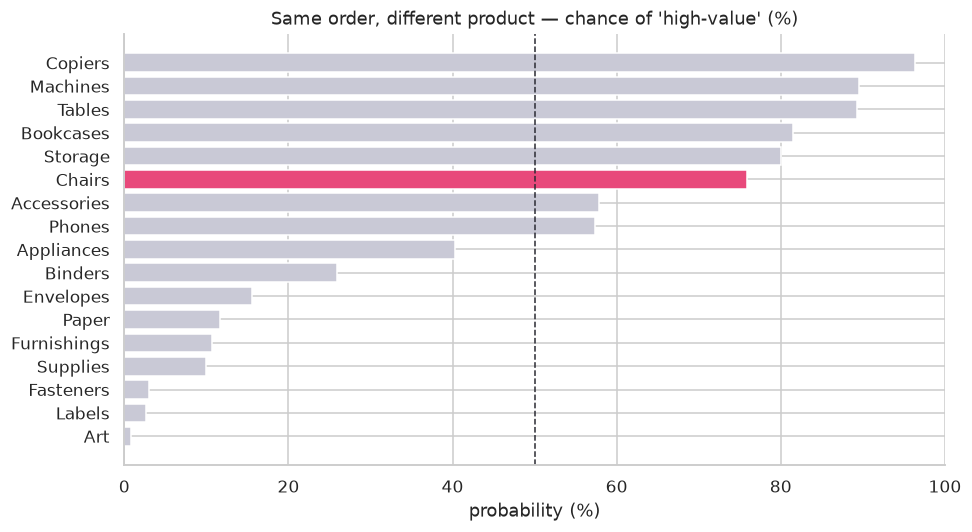

The pink bar is your product. Change any input and press ▶ again.


In [13]:
#@title 🧪 Predict a NEW order — change any input, then press ▶ { display-mode: "form" }
sub_category = "Chairs"  #@param ["Accessories", "Appliances", "Art", "Binders", "Bookcases", "Chairs", "Copiers", "Envelopes", "Fasteners", "Furnishings", "Labels", "Machines", "Paper", "Phones", "Storage", "Supplies", "Tables"]
segment = "Consumer"  #@param ["Consumer", "Corporate", "Home Office"]
region = "West"  #@param ["Central", "East", "South", "West"]
ship_mode = "Standard Class"  #@param ["Same Day", "First Class", "Second Class", "Standard Class"]
order_month = 11  #@param {type:"slider", min:1, max:12, step:1}
order_year = 2018  #@param {type:"slider", min:2015, max:2018, step:1}

try:
    predict_new_order(sub_category, segment, region, ship_mode, order_month, order_year)
except NameError:
    print("⚠️ This cell needs the cells above it to have run first.  Click  Runtime ▸ Run all  (wait until it finishes), then run this cell again.")

## 6. Your input #3 — change what counts as "high-value"
The class was *our* choice (top 25% = `\$210.57`). Type a different dollar amount: the class is rebuilt, the model is retrained, and a new confusion matrix appears. Notice how **accuracy rises just because "high-value" gets rarer** — recall tells the real story.

In [14]:
def try_cut_off(cut):
    y_new = (df["Sales"] >= cut).astype(int)
    y_tr, y_te = y_new.loc[X_train.index], y_new.loc[X_test.index]
    print(f"CLASS DEFINITION:  high-value = Sales ≥ ${cut:,.2f}")
    print(f"  → {int(y_new.sum()):,} high-value rows ({y_new.mean():.1%}) and {int((1 - y_new).sum()):,} standard rows ({1 - y_new.mean():.1%}) out of {len(y_new):,}")
    if min(y_tr.sum(), (1 - y_tr).sum()) < 20 or min(y_te.sum(), (1 - y_te).sum()) < 5:
        print("  One of the two classes is almost empty at this cut-off, so a model cannot learn it — try a number between about 25 and 1,000.")
        return
    m = make_model().fit(X_train, y_tr); p_, pr_ = m.predict(X_test), m.predict_proba(X_test)[:, 1]
    t0, f0, f1, t1 = confusion_matrix(y_te, p_).ravel()
    print(f"\nA lazy model that always says 'standard' would be {1 - y_te.mean():.1%} accurate.")
    print(f"Retrained model:  accuracy {accuracy_score(y_te, p_):.1%} · precision {precision_score(y_te, p_, zero_division=0):.2f} · "
          f"recall {recall_score(y_te, p_):.2f} · F1 {f1_score(y_te, p_):.2f} · ROC-AUC {roc_auc_score(y_te, pr_):.2f}")
    display(pd.DataFrame([[t0, f0], [f1, t1]], index=["really standard", "really high-value"], columns=["model said standard", "model said high-value"]))

In [15]:
#@title 🎚️ Change the CLASS definition — type a dollar amount, then press ▶ { display-mode: "form" }
cut_off_in_dollars = 210.57  #@param {type:"number"}

try:
    try_cut_off(cut_off_in_dollars)
except NameError:
    print("⚠️ This cell needs the cells above it to have run first.  Click  Runtime ▸ Run all  (wait until it finishes), then run this cell again.")

CLASS DEFINITION:  high-value = Sales ≥ $210.57
  → 2,450 high-value rows (25.0%) and 7,349 standard rows (75.0%) out of 9,799



A lazy model that always says 'standard' would be 75.0% accurate.
Retrained model:  accuracy 77.4% · precision 0.54 · recall 0.72 · F1 0.61 · ROC-AUC 0.85


,model said standard,model said high-value
really standard,1164,306
really high-value,137,353


## 7. The comparison — any two groups, side by side
Pick two values from the **same** list (product category, customer segment or region). The default is **Technology vs Office Supplies**: the table, four charts and a statistical test are recomputed for whichever two you choose.

*How it is made:* the rows are split by the chosen column, the same measures are calculated for each group, and a test checks that the gap is real. (This is a **comparison**, not clustering — we already know the groups.)

In [16]:
GROUPS = {"Category": ["Furniture", "Office Supplies", "Technology"], "Segment": ["Consumer", "Corporate", "Home Office"],
          "Region": ["Central", "East", "South", "West"]}

def compare_groups(a, b):
    column = next((c for c, v in GROUPS.items() if a in v and b in v), None)
    if column is None or a == b:
        print("Pick two DIFFERENT values from the same list:\n  " + "\n  ".join(f"{c}: {', '.join(v)}" for c, v in GROUPS.items())); return
    d = df[df[column].isin([a, b])].copy(); d["hv"] = d["Sales"] >= cut_off
    print(f"COMPARING  {a}  vs  {b}   (column: {column})")
    print(f"Step 0 — the rows used: {len(d):,} of {len(df):,}  ({a}: {int((d[column] == a).sum()):,} rows, {b}: {int((d[column] == b).sum()):,} rows)\n")

    def measures(x):
        yearly = x.groupby("order_year")["Sales"].sum()
        return pd.Series({"Total revenue ($)": x["Sales"].sum(), "Order lines sold": len(x), "Average sale per line ($)": x["Sales"].mean(),
                          "Typical (median) sale ($)": x["Sales"].median(), "High-value lines (%)": 100 * x["hv"].mean(),
                          "Revenue per order containing it ($)": x["Sales"].sum() / x["Order ID"].nunique(),
                          "Growth 2015 → 2018 (%)": 100 * (yearly[2018] / yearly[2015] - 1)})
    table = pd.DataFrame({v: measures(d[d[column] == v]) for v in (a, b)})
    fmt = {"Total revenue ($)": "${:,.0f}", "Order lines sold": "{:,.0f}", "Average sale per line ($)": "${:,.0f}", "Typical (median) sale ($)": "${:,.0f}",
           "High-value lines (%)": "{:.1f}%", "Revenue per order containing it ($)": "${:,.0f}", "Growth 2015 → 2018 (%)": "{:+.0f}%"}
    pretty = table.astype(object).copy()
    for row, f in fmt.items():
        pretty.loc[row] = [f.format(v) for v in table.loc[row]]
    display(pretty)

    fig, axes = plt.subplots(1, 4, figsize=(15, 3.7))
    for ax, (title, row, lab) in zip(axes, [("Total revenue", "Total revenue ($)", lambda v: f"${v/1000:,.0f}k"),
                                            ("Number of order lines", "Order lines sold", lambda v: f"{v:,.0f}"),
                                            ("Average sale per line", "Average sale per line ($)", lambda v: f"${v:,.0f}"),
                                            ("% high-value lines", "High-value lines (%)", lambda v: f"{v:.0f}%")]):
        vals = table.loc[row, [a, b]]
        bars = ax.bar([a, b], vals.values, color=[PALETTE[1], PALETTE[0]], width=0.6)
        ax.bar_label(bars, labels=[lab(v) for v in vals.values], padding=3, fontsize=11, fontweight="bold")
        ax.set_title(title, fontsize=11.5); ax.set_ylim(0, vals.max() * 1.22); ax.set_yticks([]); ax.grid(False); ax.spines["left"].set_visible(False)
    plt.tight_layout(); plt.show()

    xs, ys = d.loc[d[column] == a, "Sales"], d.loc[d[column] == b, "Sales"]
    U, p = stats.mannwhitneyu(xs, ys)
    print(f"IS THE GAP REAL?  A random {a} sale is bigger than a random {b} sale in {U / (len(xs) * len(ys)):.0%} of pairs (50% = no difference). "
          f"Test p-value: {'below 0.001' if p < 0.001 else f'{p:.3f}'}  →  {'a real difference' if p < 0.05 else 'no real difference'}.")

COMPARING  Technology  vs  Office Supplies   (column: Category)
Step 0 — the rows used: 7,722 of 9,799  (Technology: 1,813 rows, Office Supplies: 5,909 rows)



,Technology,Office Supplies
Total revenue ($),"$827,456","$705,422"
Order lines sold,"1,813","5,909"
Average sale per line ($),$456,$119
Typical (median) sale ($),$168,$27
High-value lines (%),44.6%,11.8%
Revenue per order containing it ($),$545,$192
Growth 2015 → 2018 (%),+55%,+61%


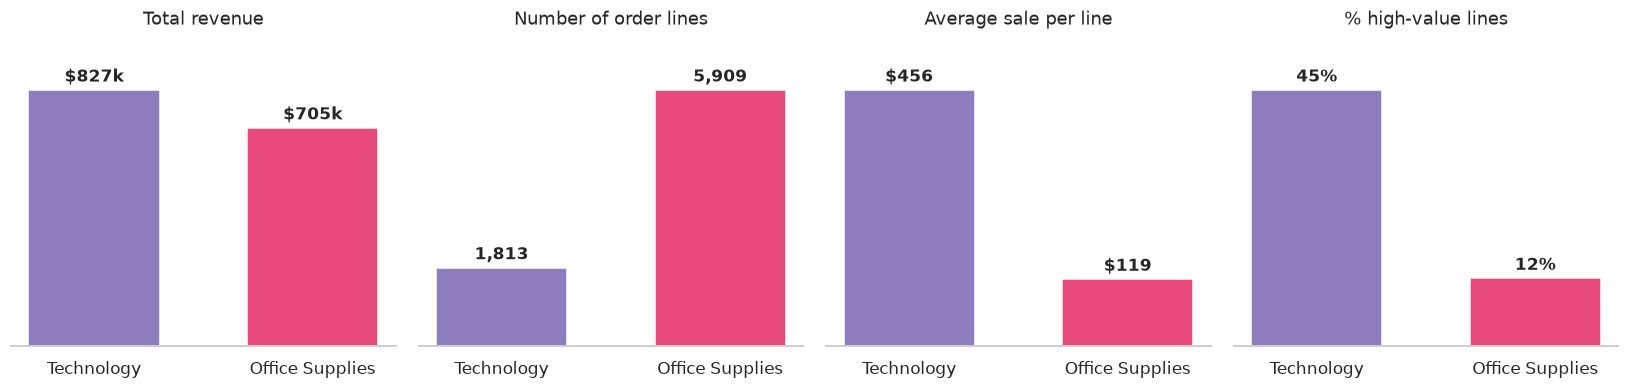

IS THE GAP REAL?  A random Technology sale is bigger than a random Office Supplies sale in 80% of pairs (50% = no difference). Test p-value: below 0.001  →  a real difference.


In [17]:
#@title ⚖️ Compare ANY two groups — pick two values from the same list, then press ▶ { display-mode: "form" }
group_A = "Technology"  #@param ["Furniture", "Office Supplies", "Technology", "Consumer", "Corporate", "Home Office", "Central", "East", "South", "West"]
group_B = "Office Supplies"  #@param ["Furniture", "Office Supplies", "Technology", "Consumer", "Corporate", "Home Office", "Central", "East", "South", "West"]

try:
    compare_groups(group_A, group_B)
except NameError:
    print("⚠️ This cell needs the cells above it to have run first.  Click  Runtime ▸ Run all  (wait until it finishes), then run this cell again.")

## Summary — what we did
1. **Dataset:** 9,799 order lines (one repeated row removed), 18 original columns.
2. **Class:** we created `high_value` from `Sales` — 1 if the sale is in the top 25% (`≥ \$210.57`), else 0.
3. **Proof:** a Random Forest, tested on rows it never saw, catches about 7 in 10 high-value orders; the confusion matrix shows every right and wrong answer.
4. **Live inputs:** a row lookup, a new-order predictor, a changeable cut-off and a two-group comparison — all recomputed on the spot.